# SpamClickbaitClassification — демонстрация решения (итоговая защита)

**Курс:** «Интеграция ИИ в разработку», УрФу × Нетология, 3 семестр · **Команда:** «Великолепная четвёрка»

**Задача:** классификация текстов сообщений Telegram на 3 класса — `normal` (обычное), `spam`, `clickbait` —
с политикой отказа `uncertain` при низкой уверенности. В целевой системе текст получается из голосового
через ASR (GigaAM-v3); здесь демонстрируется текстовая часть — ядро решения.

**Что показывает ноутбук** (по образцам практик В05, В06, В07, В09, В12, В13 курса):
1. загрузка и **валидация данных** (В06);
2. **групповой сплит без утечек** (дубликаты-шаблоны не пересекают части);
3. **3 эксперимента** TF-IDF + LogisticRegression + ансамбль-смесь, трекинг в **MLflow** (В05);
4. **политика отказа** и sweep порогов (coverage / accuracy);
5. **дрейф данных**: PSI и KS-тест + симуляция коротких голосовых реплик (В13);
6. **мини-API на FastAPI** с валидацией pydantic и структурированным логированием (В09, В12);
7. выводы и ссылки на полный проект (Docker-сервис, ансамбль RNN+CNN+LR, 84 теста).

**Запуск:** локально — `jupyter lab` из репозитория (выборка `FinalProject/data/demo_sample.csv`,
15 000 строк из `Datasets/df.csv`); в **Colab** — выполните ячейки по порядку, при запросе загрузите
`demo_sample.csv` (лежит в `FinalProject/data/`). Полный датасет (~380 МБ) не нужен.
Время выполнения ≈ 3–5 минут на CPU.

In [1]:
# Окружение: в Colab доустанавливаем зависимости, локально используем venv проекта
import sys, os, json, time, platform
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install scikit-learn pandas matplotlib mlflow fastapi httpx scipy

import numpy as np
import pandas as pd
import sklearn
from pathlib import Path

SEED = 42
LABEL_NAMES = {0: "normal", 1: "spam", 2: "clickbait"}
print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| numpy", np.__version__)

python 3.11.9 | sklearn 1.9.1 | numpy 1.26.4


## 1. Данные и валидация (практика В06)

`df.csv` — объединение ~8 Kaggle-корпусов, переведённых на русский. Известные проблемы:
мусорные строки, метка `2000`, точные дубликаты, конфликтующие метки, очень короткие тексты.
Загрузчик ниже устойчив к ним и считает статистику отсева.

In [2]:
import csv, re
from collections import Counter

_URL_RE = re.compile(r"(https?://\S+|www\.\S+)", re.IGNORECASE)
_HTML_RE = re.compile(r"<[^>]{1,200}>")
_NUM_RE = re.compile(r"\d+")
_WS_RE = re.compile(r"\s+")
_CYR_RE = re.compile(r"[а-яё]")

def clean_text(text: str) -> str:
    """demo-clean-v1: нижний регистр до масок (ссылки КАПСОМ тоже маскируются), ё→е, URL→url, числа→num."""
    t = text.lower().replace("ё", "е")
    t = _URL_RE.sub(" url ", t)
    t = _HTML_RE.sub(" ", t)
    t = _NUM_RE.sub(" num ", t)
    return _WS_RE.sub(" ", t).strip()

def load_dataset(path, max_rows=None, seed=SEED):
    stats = Counter(); pairs = {}; conflicts = set(); raw_of = {}
    n_short = 0
    with open(path, encoding="utf-8", newline="") as f:
        for row in csv.reader(f):
            if len(row) == 1 and ";" in row[0]:
                row = row[0].rsplit(";", 1)
            if len(row) != 2:
                stats["bad_column_count"] += 1; continue
            text, label_raw = row[0], row[1].strip()
            if text.strip().lower() == "text":
                stats["header"] += 1; continue
            try:
                label = int(label_raw)
            except ValueError:
                stats["no_integer_label"] += 1; continue
            if label not in (0, 1, 2):
                stats["invalid_label"] += 1; continue
            cleaned = clean_text(text)
            if len(cleaned.split()) < 3 or not _CYR_RE.search(cleaned):
                n_short += 1; continue
            if cleaned in pairs:
                if pairs[cleaned] != label: conflicts.add(cleaned)
                else: stats["duplicates"] += 1
                continue
            pairs[cleaned] = label; raw_of[cleaned] = text
    for c in conflicts:
        pairs.pop(c, None); raw_of.pop(c, None)
    items = sorted(pairs.items())
    if max_rows and max_rows < len(items):
        rng = np.random.default_rng(seed)
        y_all = np.array([l for _, l in items]); idx = []
        for lab in (0, 1, 2):
            pool = np.flatnonzero(y_all == lab)
            take = max(1, round(max_rows * len(pool) / len(items)))
            idx.extend(rng.choice(pool, size=min(take, len(pool)), replace=False))
        items = [items[i] for i in sorted(idx)]
    clean = [t for t, _ in items]
    y = np.array([l for _, l in items], dtype=int)
    report = {"kept": len(clean), "skipped": dict(stats), "conflict_texts_removed": len(conflicts), "short_removed": n_short}
    return clean, y, report

# Поиск выборки: локальный репозиторий -> текущая папка -> загрузка в Colab
candidates = [Path("../data/demo_sample.csv"), Path("FinalProject/data/demo_sample.csv"), Path("demo_sample.csv")]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    if IN_COLAB:
        from google.colab import files
        print("Загрузите demo_sample.csv из FinalProject/data/ репозитория:")
        up = files.upload()
        data_path = Path(next(iter(up)))
    else:
        raise FileNotFoundError("demo_sample.csv не найден; положите его рядом с ноутбуком")
clean, y, load_report = load_dataset(data_path)
print("Файл:", data_path)
print("Отчёт загрузки:", json.dumps(load_report, ensure_ascii=False))
print("Баланс классов:", {LABEL_NAMES[k]: int(v) for k, v in zip(*np.unique(y, return_counts=True))})

Файл: ..\data\demo_sample.csv
Отчёт загрузки: {"kept": 15000, "skipped": {"header": 1}, "conflict_texts_removed": 0, "short_removed": 0}
Баланс классов: {'normal': 9300, 'spam': 3437, 'clickbait': 2263}


In [3]:
def template_key(cleaned: str) -> str:
    """Группа близких дубликатов: спам-шаблоны, отличающиеся только числами, — одна группа."""
    return _WS_RE.sub(" ", cleaned.replace("num", " ")).strip()

def validate_dataset(texts, y):
    issues = []
    lengths = np.array([len(t.split()) for t in texts])
    counts = {LABEL_NAMES[int(k)]: int(v) for k, v in zip(*np.unique(y, return_counts=True))}
    if len(set(texts)) != len(texts): issues.append("остались точные дубликаты")
    groups = {}
    for t, lab in zip(texts, y): groups.setdefault(template_key(t), set()).add(int(lab))
    mixed = sum(1 for v in groups.values() if len(v) > 1)
    if mixed: issues.append(f"{mixed} шаблонных групп со смешанными метками")
    short = float((lengths < 4).mean())
    if short > 0.05: issues.append(f"доля текстов <4 слов: {short:.1%}")
    if min(counts.values()) / len(texts) < 0.10: issues.append("сильный дисбаланс классов")
    return {"n_rows": len(texts), "class_counts": counts, "template_groups": len(groups),
            "words_median": float(np.median(lengths)), "words_p95": float(np.percentile(lengths, 95)),
            "issues": issues}

validation = validate_dataset(clean, y)
print(json.dumps(validation, ensure_ascii=False, indent=1))
if validation["issues"]:
    print("ВНИМАНИЕ, найденные проблемы данных:", validation["issues"])
else:
    print("Валидация пройдена: дубликатов и конфликтов нет, баланс допустимый")

{
 "n_rows": 15000,
 "class_counts": {
  "normal": 9300,
  "spam": 3437,
  "clickbait": 2263
 },
 "template_groups": 15000,
 "words_median": 19.0,
 "words_p95": 243.0,
 "issues": []
}
Валидация пройдена: дубликатов и конфликтов нет, баланс допустимый


## 2. Групповой сплит без утечек

Случайный `train_test_split` завышает метрики: близкие дубликаты попадают и в train, и в test
(в аудите проекта 617 из 2059 проверенных тестовых кандидатов имели сходство ≥95% с fit).
Здесь группа = `template_key`, метка группы — самая частая; делим **группы** 72/8/20 (fit/dev/test).

In [4]:
def group_split(texts, y, seed=SEED):
    groups = {}
    for i, t in enumerate(texts): groups.setdefault(template_key(t), []).append(i)
    by_class = {0: [], 1: [], 2: []}
    for key, idx in groups.items():
        c = Counter(int(y[i]) for i in idx)
        lab = min(c, key=lambda k: (-c[k], k))
        by_class[lab].append(key)
    rng = np.random.default_rng(seed)
    parts = {"fit": [], "dev": [], "test": []}
    for lab in (0, 1, 2):
        keys = sorted(by_class[lab]); rng.shuffle(keys)
        n_test = max(1, round(0.20 * len(keys)))
        n_dev = max(1, round(0.10 * (len(keys) - n_test)))
        parts["test"] += [i for k in keys[:n_test] for i in groups[k]]
        parts["dev"] += [i for k in keys[n_test:n_test+n_dev] for i in groups[k]]
        parts["fit"] += [i for k in keys[n_test+n_dev:] for i in groups[k]]
    return tuple(np.array(sorted(v)) for v in (parts["fit"], parts["dev"], parts["test"]))

fit_idx, dev_idx, test_idx = group_split(clean, y)
X_fit = [clean[i] for i in fit_idx]; X_dev = [clean[i] for i in dev_idx]; X_test = [clean[i] for i in test_idx]
y_fit, y_dev, y_test = y[fit_idx], y[dev_idx], y[test_idx]
kf = {template_key(clean[i]) for i in fit_idx}
kd = {template_key(clean[i]) for i in dev_idx}
kt = {template_key(clean[i]) for i in test_idx}
assert not (kf & kd) and not (kf & kt) and not (kd & kt), "утечка групп!"
print(f"fit={len(fit_idx)}, dev={len(dev_idx)}, test={len(test_idx)}; пересечений групп нет")
print("Баланс test:", {LABEL_NAMES[k]: int(v) for k, v in zip(*np.unique(y_test, return_counts=True))})

fit=10800, dev=1200, test=3000; пересечений групп нет
Баланс test: {'normal': 1860, 'spam': 687, 'clickbait': 453}


## 3. Эксперименты E1–E4 и трекинг в MLflow (практика В05)

Сравниваем три конфигурации TF-IDF + LogisticRegression (уменьшенные аналоги конфигов
`baseline`/`exp4` тренера `inference-api/training/train.py`) и ансамбль-смесь вероятностей:

| Прогон | Признаки | Идея |
|---|---|---|
| E1 | word 1–2 граммамы | базовая словесная модель |
| E2 | char_wb 3–5 | устойчивость к опечаткам и словоформам |
| E3 | word + char (вес char 0.6) | объединение признаков (аналог exp4) |
| E4 | смесь вероятностей E1–E3 | веса подбираются **только на dev**, test — один раз |

Основная метрика — **macro-F1** (классы несбалансированы; accuracy маскирует провал по кликбейту).
Каждый прогон логируется в MLflow: параметры, метрики, версия sklearn, seed.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

_WORD = dict(ngram_range=(1, 2), min_df=3, max_features=50_000, sublinear_tf=True)
_CHAR = dict(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=50_000, sublinear_tf=True)
CONFIGS = {
    "E1_word_only": {"branches": ["word"], "w": None},
    "E2_char_only": {"branches": ["char"], "w": None},
    "E3_union_weighted": {"branches": ["word", "char"], "w": {"word": 1.0, "char": 0.6}},
}

def build_pipeline(cfg):
    branches = []
    if "word" in cfg["branches"]: branches.append(("word", TfidfVectorizer(**_WORD)))
    if "char" in cfg["branches"]: branches.append(("char", TfidfVectorizer(**_CHAR)))
    tfidf = branches[0][1] if len(branches) == 1 else FeatureUnion(branches, transformer_weights=cfg["w"])
    return Pipeline([("tfidf", tfidf),
                     ("clf", LogisticRegression(C=10.0, class_weight="balanced", max_iter=1000, random_state=SEED))])

def evaluate(y_true, y_pred):
    pr, rc, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    return {"accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
            "macro_f1": round(float(f1_score(y_true, y_pred, average="macro", zero_division=0)), 4),
            "f1_normal": round(float(f1[0]), 4), "f1_spam": round(float(f1[1]), 4),
            "f1_clickbait": round(float(f1[2]), 4),
            "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1, 2]).tolist()}

import mlflow
mlflow.set_tracking_uri("sqlite:///mlflow_demo.db")
if mlflow.get_experiment_by_name("demo-solution-notebook") is None:
    mlflow.create_experiment("demo-solution-notebook", artifact_location=Path("mlartifacts").resolve().as_uri())
mlflow.set_experiment("demo-solution-notebook")

runs = []; dev_probas = []; test_probas = []; models = {}
for name, cfg in CONFIGS.items():
    t0 = time.perf_counter()
    model = build_pipeline(cfg)
    model.fit(X_fit, y_fit)
    fit_time = time.perf_counter() - t0
    p_dev = model.predict_proba(X_dev); p_test = model.predict_proba(X_test)
    dev_probas.append(p_dev); test_probas.append(p_test); models[name] = model
    m_dev = evaluate(y_dev, p_dev.argmax(1)); m_test = evaluate(y_test, p_test.argmax(1))
    runs.append({"run": name, "dev_macro_f1": m_dev["macro_f1"], **{f"test_{k}": v for k, v in m_test.items() if k != "confusion_matrix"}, "fit_sec": round(fit_time, 1)})
    with mlflow.start_run(run_name=name):
        mlflow.log_params({"config": name, "seed": SEED, "n_fit": len(X_fit), "sklearn": sklearn.__version__})
        mlflow.log_metrics({"dev_macro_f1": m_dev["macro_f1"], "test_macro_f1": m_test["macro_f1"],
                            "test_accuracy": m_test["accuracy"], "test_f1_clickbait": m_test["f1_clickbait"],
                            "fit_time_sec": round(fit_time, 1)})
    print(f"{name}: dev macro-F1={m_dev['macro_f1']:.4f}, test macro-F1={m_test['macro_f1']:.4f}, acc={m_test['accuracy']:.4f} ({fit_time:.0f} с)")

2026/11/17 10:32:35 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at E:\SpamClickbaitClassification\venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/11/17 10:32:35 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/17 10:32:35 INFO mlflow.store.db.utils: Updating database tables


E1_word_only: dev macro-F1=0.7087, test macro-F1=0.7150, acc=0.7700 (3 с)


E2_char_only: dev macro-F1=0.7309, test macro-F1=0.7307, acc=0.7750 (10 с)


E3_union_weighted: dev macro-F1=0.7344, test macro-F1=0.7340, acc=0.7883 (11 с)


Веса ансамбля (E1, E2, E3): [0.3, 0.5, 0.2]


,dev_macro_f1,test_macro_f1,test_accuracy,test_f1_normal,test_f1_spam,test_f1_clickbait
run,,,,,,
E1_word_only,0.7087,0.7150,0.7700,0.8208,0.8196,0.5047
E2_char_only,0.7309,0.7307,0.7750,0.8186,0.8427,0.5307
E3_union_weighted,0.7344,0.7340,0.7883,0.8346,0.8553,0.5121
E4_blend,0.7428,0.7455,0.7933,0.8362,0.8580,0.5425


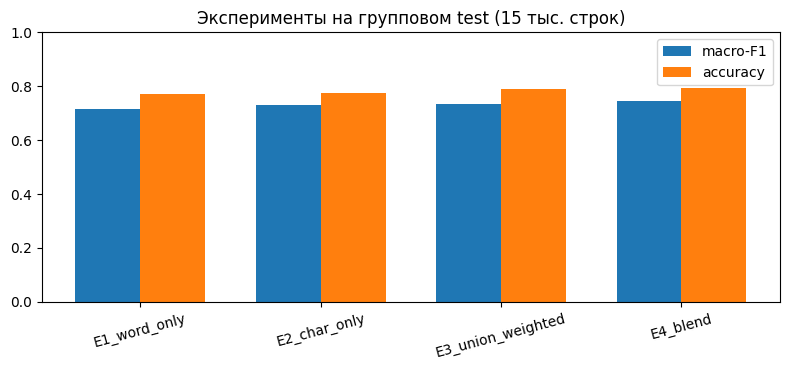

In [6]:
def blend_proba(probas, weights):
    w = np.asarray(weights, float); w = w / w.sum()
    return sum(wi * p for wi, p in zip(w, probas))

def select_weights(dev_probas, y_dev, step=0.1):
    grid = np.arange(0, 1 + 1e-9, step)
    best_w, best_f1 = None, -1.0
    for w0 in grid:
        for w1 in grid:
            w2 = 1 - w0 - w1
            if w2 < -1e-9: continue
            w = [round(float(w0), 2), round(float(w1), 2), round(float(w2), 2)]
            f1 = f1_score(y_dev, blend_proba(dev_probas, w).argmax(1), average="macro")
            if f1 > best_f1: best_w, best_f1 = w, float(f1)
    return best_w, best_f1

weights, dev_f1 = select_weights(dev_probas, y_dev)
p_blend = blend_proba(test_probas, weights)
m4 = evaluate(y_test, p_blend.argmax(1))
runs.append({"run": "E4_blend", "dev_macro_f1": round(dev_f1, 4), **{f"test_{k}": v for k, v in m4.items() if k != "confusion_matrix"}, "fit_sec": 0.0})
with mlflow.start_run(run_name="E4_blend"):
    mlflow.log_params({"weights_E1_E2_E3": str(weights), "selection_split": "dev", "seed": SEED})
    mlflow.log_metrics({"dev_macro_f1": dev_f1, "test_macro_f1": m4["macro_f1"], "test_accuracy": m4["accuracy"]})
print("Веса ансамбля (E1, E2, E3):", weights)

df_runs = pd.DataFrame(runs).set_index("run")
display(df_runs[["dev_macro_f1", "test_macro_f1", "test_accuracy", "test_f1_normal", "test_f1_spam", "test_f1_clickbait"]])

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(df_runs))
ax.bar(x - 0.18, df_runs["test_macro_f1"], 0.36, label="macro-F1")
ax.bar(x + 0.18, df_runs["test_accuracy"], 0.36, label="accuracy")
ax.set_xticks(x, df_runs.index, rotation=15); ax.set_ylim(0, 1); ax.legend()
ax.set_title("Эксперименты на групповом test (15 тыс. строк)")
fig.tight_layout(); plt.show()

## 4. Политика отказа: `uncertain` вместо ошибочной метки

Как в `inference-api/app/model.py`: если лучший класс — `spam`, требуется повышенный порог
`τ_spam = 0.65` (цена ложного «спама» для обычного сообщения высока); иначе `τ = 0.55`.
Ниже порога — `status="uncertain"`, `label=null`, **никогда** не «обычное».

In [7]:
TAU, TAU_SPAM = 0.55, 0.65

def decide(proba, tau=TAU, tau_spam=TAU_SPAM):
    out = []
    for p in np.atleast_2d(proba):
        k = int(p.argmax()); thr = tau_spam if k == 1 else tau
        if p[k] >= thr:
            out.append({"status": "classified", "label": LABEL_NAMES[k], "confidence": round(float(p[k]), 3)})
        else:
            out.append({"status": "uncertain", "label": None, "confidence": round(float(p[k]), 3), "reason": "low_confidence"})
    return out

def policy_metrics(y_true, proba, tau=TAU, tau_spam=TAU_SPAM):
    d = decide(proba, tau, tau_spam)
    mask = np.array([x["status"] == "classified" for x in d])
    pred = proba.argmax(1)
    return {"coverage": round(float(mask.mean()), 4),
            "accuracy_classified": round(float(accuracy_score(y_true[mask], pred[mask])), 4) if mask.any() else None,
            "accuracy_all": round(float(accuracy_score(y_true, pred)), 4)}

p_best = test_probas[2]  # E3
sweep = [{"tau": round(float(t), 2), "tau_spam": round(float(t) + 0.1, 2), **policy_metrics(y_test, p_best, float(t), float(t) + 0.1)}
         for t in np.arange(0.40, 0.85, 0.05)]
display(pd.DataFrame(sweep))
print("Рабочая точка τ=0.55/τ_spam=0.65:", policy_metrics(y_test, p_best))

examples = ["Вам одобрен кредит на 300000 рублей! Перезвоните по номеру 8-800",
            "Ты не поверишь, что сделала эта знаменитость! Все ахнули",
            "Буду через десять минут, возьми хлеба",
            "Здравствуйте, уточните пожалуйста детали"]
p_ex = models["E3_union_weighted"].predict_proba([clean_text(t) for t in examples])
for t, d in zip(examples, decide(p_ex)):
    print(f"{d['status']:>10} | {str(d['label']):>9} | conf={d['confidence']:.2f} | {t[:60]}")

,tau,tau_spam,coverage,accuracy_classified,accuracy_all
0,0.40,0.50,0.9903,0.7937,0.7883
1,0.45,0.55,0.9737,0.7966,0.7883
2,0.50,0.60,0.9547,0.8017,0.7883
3,0.55,0.65,0.9063,0.8172,0.7883
4,0.60,0.70,0.8547,0.8323,0.7883
5,0.65,0.75,0.8020,0.8466,0.7883
6,0.70,0.80,0.7450,0.8595,0.7883
7,0.75,0.85,0.6830,0.8755,0.7883
8,0.80,0.90,0.6140,0.8893,0.7883


Рабочая точка τ=0.55/τ_spam=0.65: {'coverage': 0.9063, 'accuracy_classified': 0.8172, 'accuracy_all': 0.7883}
classified |      spam | conf=0.78 | Вам одобрен кредит на 300000 рублей! Перезвоните по номеру 8
classified | clickbait | conf=0.84 | Ты не поверишь, что сделала эта знаменитость! Все ахнули
 uncertain |      None | conf=0.48 | Буду через десять минут, возьми хлеба
classified |      spam | conf=0.82 | Здравствуйте, уточните пожалуйста детали


## 5. Дрейф данных (практика В13)

**PSI** по распределению длины текста (в словах): <0.1 стабильно, 0.1–0.25 умеренный сдвиг,
>0.25 значимый дрейф. Дополнительно KS-тест. Симулируем дрейф «короткие голосовые реплики»:
обрезаем test до 8 слов — так выглядят транскрипты коротких voice-сообщений.
Дрейф — сигнал к разметке и анализу, а не к автоматическому переобучению.

fit vs test: PSI=0.0020 (stable), KS stat=0.014, p=0.750


Симуляция 'короткие реплики': PSI=9.6508 (significant)
macro-F1: 0.7340 -> 0.6099 (Δ=-0.1241)
F1 spam: 0.8553 -> 0.5856; F1 clickbait: 0.5121 -> 0.4665


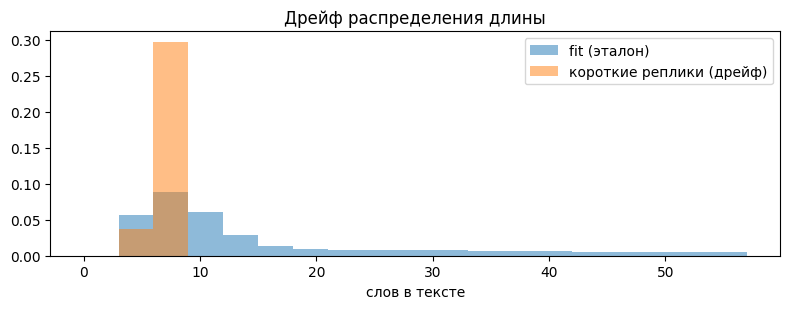

In [8]:
from scipy import stats

def psi(reference, current, bins=10, eps=1e-6):
    ref = np.asarray(reference, float); cur = np.asarray(current, float)
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3: edges = np.array([ref.min() - 1, ref.min(), ref.max() + 1])
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), eps, None)
    c = np.clip(np.histogram(cur, edges)[0] / len(cur), eps, None)
    return float(np.sum((c - r) * np.log(c / r)))

len_fit = np.array([len(t.split()) for t in X_fit])
len_test = np.array([len(t.split()) for t in X_test])
short_test = [" ".join(t.split()[:8]) for t in X_test]
len_short = np.array([len(t.split()) for t in short_test])

psi_normal = psi(len_fit, len_test)
ks = stats.ks_2samp(len_fit, len_test)
print(f"fit vs test: PSI={psi_normal:.4f} (stable), KS stat={ks.statistic:.3f}, p={ks.pvalue:.3f}")

p_short = models["E3_union_weighted"].predict_proba(short_test)
m_short = evaluate(y_test, p_short.argmax(1))
psi_drift = psi(len_fit, len_short)
print(f"Симуляция 'короткие реплики': PSI={psi_drift:.4f} (significant)")
print(f"macro-F1: {runs[2]['test_macro_f1']:.4f} -> {m_short['macro_f1']:.4f} (Δ={m_short['macro_f1'] - runs[2]['test_macro_f1']:+.4f})")
print(f"F1 spam: {runs[2]['test_f1_spam']:.4f} -> {m_short['f1_spam']:.4f}; F1 clickbait: {runs[2]['test_f1_clickbait']:.4f} -> {m_short['f1_clickbait']:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.arange(0, 60, 3)
ax.hist(np.clip(len_fit, 0, 60), bins=bins, alpha=0.5, density=True, label="fit (эталон)")
ax.hist(np.clip(len_short, 0, 60), bins=bins, alpha=0.5, density=True, label="короткие реплики (дрейф)")
ax.set_xlabel("слов в тексте"); ax.legend(); ax.set_title("Дрейф распределения длины")
fig.tight_layout(); plt.show()

## 6. Мини-API на FastAPI (практики В09 и В12)

Тот же контракт, что у боевого `inference-api`: `POST /predict`, `GET /healthcheck`, `GET /model-info`;
pydantic-валидация входа (422 на мусор), политика отказа, версионирование модели.
Middleware пишет **структурированные JSON-логи без текста сообщения** (приватность):
`request_id`, путь, статус, длительность, версия модели. Это упрощённая копия подхода
`app/logs.py` + middleware из практики В12; в полном проекте сервис упакован в Docker
(`compose.yaml`, healthcheck, 503 при незагруженной модели).

In [9]:
import logging, uuid
from fastapi import FastAPI, Request
from fastapi.responses import JSONResponse
from pydantic import BaseModel, field_validator
from fastapi.testclient import TestClient

MODEL_VERSION = "tfidf-logreg@demo-e3"
api = FastAPI(title="SpamClickbait demo API", version="1.0")
trained_model = models["E3_union_weighted"]

class PredictRequest(BaseModel):
    text: str
    threshold: float | None = None

    @field_validator("text")
    @classmethod
    def text_must_contain_letters(cls, v: str) -> str:
        v = v.strip()
        if len(v) < 2 or not re.search(r"[а-яёa-z]", v, re.IGNORECASE):
            raise ValueError("текст должен содержать буквы")
        return v

@api.middleware("http")
async def log_requests(request: Request, call_next):
    rid = str(uuid.uuid4())[:8]
    t0 = time.perf_counter()
    response = await call_next(request)
    ms = round((time.perf_counter() - t0) * 1000, 1)
    logging.getLogger("api").info(json.dumps({
        "request_id": rid, "path": request.url.path, "status": response.status_code,
        "latency_ms": ms, "model_version": MODEL_VERSION}, ensure_ascii=False))
    response.headers["X-Request-Id"] = rid
    return response

@api.get("/healthcheck")
def healthcheck():
    return {"status": "ok", "model_loaded": trained_model is not None}

@api.get("/model-info")
def model_info():
    return {"model_version": MODEL_VERSION, "classes": list(LABEL_NAMES.values()),
            "policy": {"tau": TAU, "tau_spam": TAU_SPAM}, "sklearn": sklearn.__version__}

@api.post("/predict")
def predict(req: PredictRequest):
    p = trained_model.predict_proba([clean_text(req.text)])[0]
    tau = req.threshold if req.threshold is not None else TAU
    d = decide(p, tau=tau, tau_spam=max(tau + 0.10, TAU_SPAM))[0]
    return {**d, "scores": {LABEL_NAMES[i]: round(float(p[i]), 4) for i in range(3)},
            "model_version": MODEL_VERSION}

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
client = TestClient(api)
print("GET /healthcheck ->", client.get("/healthcheck").json())
r = client.post("/predict", json={"text": "Вам одобрен кредит на 300000 рублей! Перезвоните 8-800"})
print("POST /predict (спам) ->", r.status_code, json.dumps(r.json(), ensure_ascii=False))
r = client.post("/predict", json={"text": "Буду через десять минут, возьми хлеба"})
print("POST /predict (обычное) ->", r.status_code, json.dumps(r.json(), ensure_ascii=False))
r = client.post("/predict", json={"text": "123 !!!"})
print("POST /predict (мусор) ->", r.status_code, "(ожидается 422)")
assert r.status_code == 422
r = client.post("/predict", json={"text": "Ты не поверишь, что случилось дальше! Шокирующая правда"})
print("POST /predict (кликбейт) ->", r.status_code, json.dumps(r.json(), ensure_ascii=False))

E:\SpamClickbaitClassification\venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
{"request_id": "0272888b", "path": "/healthcheck", "status": 200, "latency_ms": 2.1, "model_version": "tfidf-logreg@demo-e3"}


HTTP Request: GET http://testserver/healthcheck "HTTP/1.1 200 OK"


{"request_id": "6a70ca5d", "path": "/predict", "status": 200, "latency_ms": 5.1, "model_version": "tfidf-logreg@demo-e3"}


HTTP Request: POST http://testserver/predict "HTTP/1.1 200 OK"


{"request_id": "c8539c8a", "path": "/predict", "status": 200, "latency_ms": 3.2, "model_version": "tfidf-logreg@demo-e3"}


HTTP Request: POST http://testserver/predict "HTTP/1.1 200 OK"


{"request_id": "22de1c83", "path": "/predict", "status": 422, "latency_ms": 1.7, "model_version": "tfidf-logreg@demo-e3"}


HTTP Request: POST http://testserver/predict "HTTP/1.1 422 Unprocessable Entity"


{"request_id": "a7b4eac3", "path": "/predict", "status": 200, "latency_ms": 3.3, "model_version": "tfidf-logreg@demo-e3"}


HTTP Request: POST http://testserver/predict "HTTP/1.1 200 OK"


GET /healthcheck -> {'status': 'ok', 'model_loaded': True}
POST /predict (спам) -> 200 {"status": "uncertain", "label": null, "confidence": 0.561, "reason": "low_confidence", "scores": {"normal": 0.3857, "spam": 0.5606, "clickbait": 0.0537}, "model_version": "tfidf-logreg@demo-e3"}
POST /predict (обычное) -> 200 {"status": "uncertain", "label": null, "confidence": 0.483, "reason": "low_confidence", "scores": {"normal": 0.4826, "spam": 0.0977, "clickbait": 0.4197}, "model_version": "tfidf-logreg@demo-e3"}
POST /predict (мусор) -> 422 (ожидается 422)
POST /predict (кликбейт) -> 200 {"status": "classified", "label": "clickbait", "confidence": 0.76, "scores": {"normal": 0.099, "spam": 0.1407, "clickbait": 0.7603}, "model_version": "tfidf-logreg@demo-e3"}


## 7. Выводы

1. **Данные решают**: очистка от дублей/конфликтов и групповой сплит дают честную (более низкую)
   оценку, чем случайный сплит в ранних ноутбуках. Метрики на `df.csv` всё равно завышены относительно
   реальных голосовых — классы взяты из разных источников (риск R-36 ревью).
2. **Объединение word+char признаков (E3) и смесь (E4)** устойчивее одиночных ветвей;
   самая сложная граница — `clickbait` vs `normal`.
3. **Политика отказа** повышает accuracy среди уверенных ответов ценой coverage;
   порог — продуктовый параметр, а не константа.
4. **Короткие реплики — подтверждённый риск**: симуляция дрейфа заметно роняет качество;
   в продакшене это ловится PSI-мониторингом длины и долей `uncertain`.
5. **Контракт и логи готовы к сервису**: pydantic-валидация, версионирование, JSON-логи без текста.

**Полный проект** (`E:\SpamClickbaitClassification` / GitHub `pudoff/SpamClickbaitClassification`):
ансамбль BiGRU+attention / char-CNN / TF-IDF-LR (`rnn-cnn-lr@ensemble-20261018`, macro-F1 0.8347
на групповом test 86 830 строк), FastAPI в Docker, 84 теста, MLflow, Model Card, BPMN переобучения,
концепт v2 с ASR-конвейером (GigaAM-v3 + Silero VAD). Итоговые материалы защиты — в `FinalProject/`:
отчёт, презентация, тест-план, планы деплоя и мониторинга.

In [10]:
summary = {
    "notebook": "demo_solution",
    "dataset": str(data_path), "n_rows": len(clean),
    "split": {"fit": len(fit_idx), "dev": len(dev_idx), "test": len(test_idx)},
    "runs": runs, "blend_weights": weights,
    "policy_working_point": policy_metrics(y_test, p_best),
    "drift": {"psi_fit_vs_test": round(psi_normal, 4), "psi_short_simulation": round(psi_drift, 4),
              "macro_f1_before": runs[2]["test_macro_f1"], "macro_f1_after_short": m_short["macro_f1"]},
    "env": {"python": platform.python_version(), "sklearn": sklearn.__version__},
}
Path("demo_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Сводка сохранена в demo_summary.json")
print(json.dumps(summary["drift"], ensure_ascii=False))

Сводка сохранена в demo_summary.json
{"psi_fit_vs_test": 0.002, "psi_short_simulation": 9.6508, "macro_f1_before": 0.734, "macro_f1_after_short": 0.6099}
